In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Loading & Initial Exploration

In [2]:
# Loading the dataset
df_drcat = pd.read_csv("./data/train_v2_drcat_02.csv")
df_ai_2026 = pd.read_csv("./data/ai_vs_human_text_2026.csv")
df_ai_human = pd.read_csv("./data/AI_Human.csv")

In [3]:
datasets = {
    'AI_Human': df_ai_human,
    'train_v2_drcat_02': df_drcat,
    'ai_vs_human_text_2026': df_ai_2026
}

for name, df in datasets.items():
    print(f"The {name} dataset has {df.shape[0]:,} rows and {df.shape[1]} columns")

The AI_Human dataset has 487,235 rows and 2 columns
The train_v2_drcat_02 dataset has 44,868 rows and 5 columns
The ai_vs_human_text_2026 dataset has 2,000 rows and 9 columns


In [4]:
print("AI Human Dataset")
display(df_ai_human.head(5))
print("Train V2 DRCAT Dataset")
display(df_drcat.head(5))
print("AI vs Human text 2026 Dataset")
display(df_ai_2026.head(5))

AI Human Dataset


,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0


Train V2 DRCAT Dataset


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False
3,Phones & Driving\n\nDrivers should not be able...,0,Phones and driving,persuade_corpus,False
4,Cell Phone Operation While Driving\n\nThe abil...,0,Phones and driving,persuade_corpus,False


AI vs Human text 2026 Dataset


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [5]:
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(df.info())
    print()

--- AI_Human ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 487235 entries, 0 to 487234
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   text       487235 non-null  object 
 1   generated  487235 non-null  float64
dtypes: float64(1), object(1)
memory usage: 7.4+ MB
None

--- train_v2_drcat_02 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44868 entries, 0 to 44867
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text           44868 non-null  object
 1   label          44868 non-null  int64 
 2   prompt_name    44868 non-null  object
 3   source         44868 non-null  object
 4   RDizzl3_seven  44868 non-null  bool  
dtypes: bool(1), int64(1), object(3)
memory usage: 1.4+ MB
None

--- ai_vs_human_text_2026 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column    

In [6]:
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(df.dtypes)
    print()

--- AI_Human ---
text          object
generated    float64
dtype: object

--- train_v2_drcat_02 ---
text             object
label             int64
prompt_name      object
source           object
RDizzl3_seven      bool
dtype: object

--- ai_vs_human_text_2026 ---
text_id                 object
label                   object
source_model            object
domain                  object
text_content            object
topic_hint              object
word_count               int64
avg_sentence_length    float64
generation_method       object
dtype: object



# Checking for Missing values

In [7]:
for name, df in datasets.items():
    print(f"--- {name} ---")
    print("Missing values:\n", df.isnull().sum())
    print("Fully duplicated rows:", df.duplicated().sum())
    print()

--- AI_Human ---
Missing values:
 text         0
generated    0
dtype: int64
Fully duplicated rows: 0

--- train_v2_drcat_02 ---
Missing values:
 text             0
label            0
prompt_name      0
source           0
RDizzl3_seven    0
dtype: int64
Fully duplicated rows: 0

--- ai_vs_human_text_2026 ---
Missing values:
 text_id                0
label                  0
source_model           0
domain                 0
text_content           0
topic_hint             0
word_count             0
avg_sentence_length    0
generation_method      0
dtype: int64
Fully duplicated rows: 0



# Renaming key data columns to common points

In [10]:
df_ai_2026 = df_ai_2026.rename(columns={'text_content': 'text'})

df_ai_human['is_ai'] = df_ai_human['generated'].astype(int)
df_drcat['is_ai']    = df_drcat['label'].astype(int)
df_ai_2026['is_ai']  = (df_ai_2026['label'] == 'ai').astype(int)

datasets = {
    'AI_Human': df_ai_human,
    'train_v2_drcat_02': df_drcat,
    'ai_vs_human_text_2026': df_ai_2026,
}

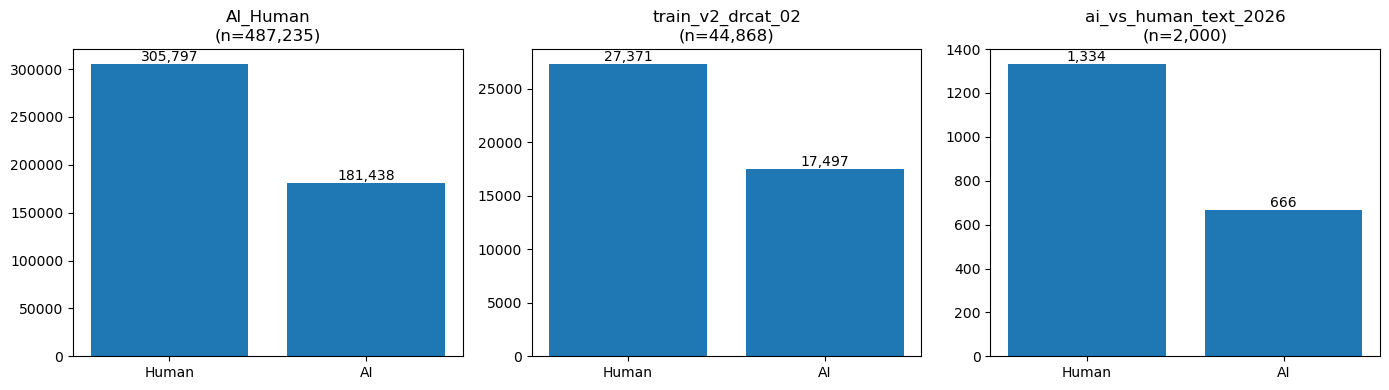

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    counts = df['is_ai'].value_counts().sort_index()
    ax.bar(['Human', 'AI'], counts.values)
    ax.set_title(f"{name}\n(n={len(df):,})")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [12]:
for df in datasets.values():
    df['char_length'] = df['text'].str.len()
    df['word_count']  = df['text'].str.split().str.len()

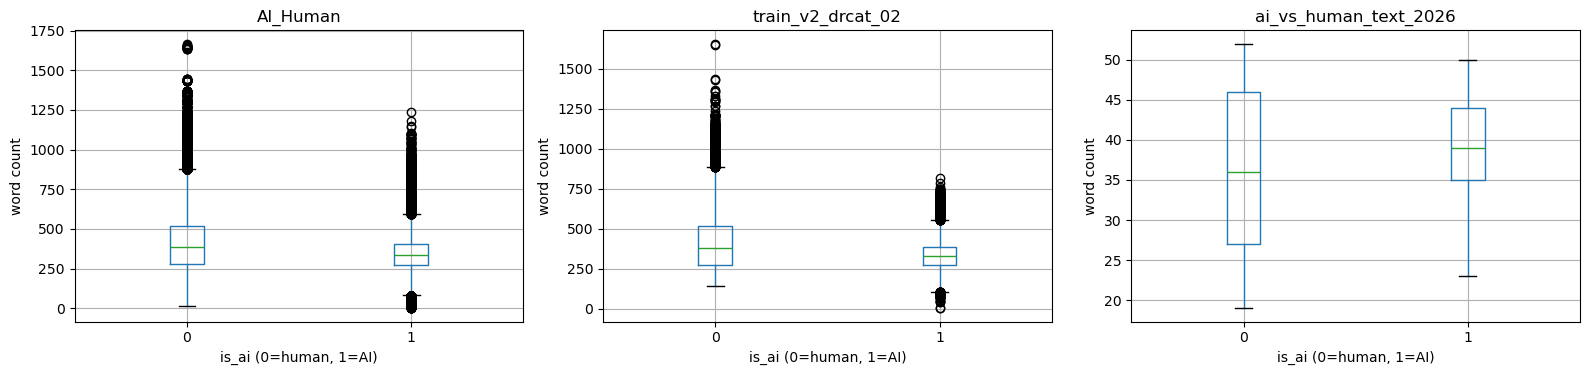

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    df.boxplot(column='word_count', by='is_ai', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('is_ai (0=human, 1=AI)')
    ax.set_ylabel('word count')
plt.suptitle('')
plt.tight_layout()
plt.show()